# UpSet Plot

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific:* Domain-neutral statistics and research plots: effect sizes, meta-analysis, agreement, omics, replicates and visual inference.

## Design purpose

Shows how several sets overlap. A matrix of dots marks which sets make up each intersection, and a bar above each column gives its size. It scales to many sets where Venn and Euler diagrams become unreadable.

## When to use

- Show the overlap of more than three sets (comorbidities, gene lists, mutation co-occurrence, survey multi-select answers)
- Rank intersections by size to find the most common combinations
- Compare exact intersection counts rather than reading shapes

## Avoid when

- There are only two or three sets and the audience expects a Venn diagram
- The number of non-empty intersections is huge (keep the top 15–25 and say so)

## Alternatives

- Venn diagram (2–3 sets)
- Co-occurrence heatmap (pairwise overlaps only)

## Design tips

- Use it instead of a Venn diagram for more than three sets, because Venn regions become impossible to size or read
- Sort intersections by size and show only the largest ones
- Show each set's total size as horizontal bars beside the matrix
- Highlight one intersection of interest and keep the rest neutral

## Example

Comorbidity patterns among 1,000 synthetic patients across five conditions (hypertension, diabetes, obesity, chronic kidney disease, COPD).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(21)
n = 1000
age = rng.uniform(30, 85, n)
obesity = rng.random(n) < 0.30
hypertension = rng.random(n) < 0.15 + 0.006 * (age - 30) + 0.15 * obesity
diabetes = rng.random(n) < 0.05 + 0.15 * obesity + 0.12 * hypertension
ckd = rng.random(n) < 0.02 + 0.10 * diabetes + 0.08 * hypertension
copd = rng.random(n) < 0.04 + 0.002 * (age - 30)
df = pd.DataFrame({"Hypertension": hypertension, "Diabetes": diabetes, "Obesity": obesity,
                   "CKD": ckd, "COPD": copd})
sets = list(df.columns)
combos = (df[df.any(axis=1)].value_counts().rename("count").reset_index()
          .sort_values("count", ascending=False).head(15).reset_index(drop=True))
combos

,Hypertension,Diabetes,Obesity,CKD,COPD,count
0,True,False,False,False,False,146
1,False,False,True,False,False,111
2,True,False,True,False,False,75
3,False,False,False,False,True,36
4,True,True,True,False,False,31
5,False,True,True,False,False,24
6,True,True,False,False,False,23
7,False,True,False,False,False,15
8,True,False,True,True,False,13
9,True,False,False,False,True,13


### Plot

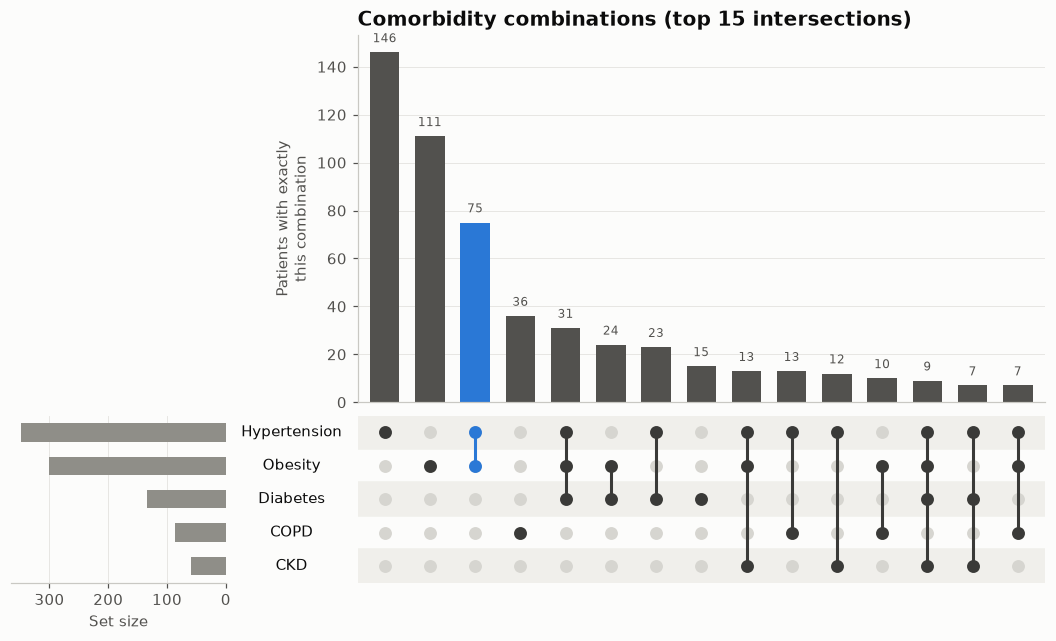

In [3]:
set_sizes = df.sum().sort_values()
sets_order = list(set_sizes.index)               # bottom-to-top rows
n_sets, n_cols = len(sets_order), len(combos)
degree = combos[sets].sum(axis=1)
highlight = int(degree[degree >= 2].index[0]) if (degree >= 2).any() else 0   # largest multi-condition combo

fig = plt.figure(figsize=(10, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 0.55, 3.2], height_ratios=[2.2, 1], wspace=0.02, hspace=0.05)
ax_bar = fig.add_subplot(gs[0, 2])
ax_mat = fig.add_subplot(gs[1, 2], sharex=ax_bar)
ax_set = fig.add_subplot(gs[1, 0], sharey=ax_mat)
ax_lab = fig.add_subplot(gs[1, 1], sharey=ax_mat)

x = np.arange(n_cols)
colors = [PALETTE[0] if i == highlight else "#52514e" for i in x]
ax_bar.bar(x, combos["count"], color=colors, width=0.65)
for i, v in enumerate(combos["count"]):
    ax_bar.text(i, v + 3, str(v), ha="center", va="bottom", fontsize=8, color="#52514e")
ax_bar.set_ylabel("Patients with exactly\nthis combination")
ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)
ax_bar.grid(axis="x", visible=False)
ax_bar.set_title("Comorbidity combinations (top 15 intersections)")

for r in range(n_sets):
    if r % 2 == 0:
        ax_mat.axhspan(r - 0.5, r + 0.5, color="#f0efeb", zorder=0)
for i, row in combos.iterrows():
    members = [sets_order.index(s) for s in sets if row[s]]
    col = PALETTE[0] if i == highlight else "#3a3a38"
    ax_mat.scatter([i] * n_sets, range(n_sets), s=55, color="#d6d5d0", zorder=2)
    ax_mat.scatter([i] * len(members), members, s=55, color=col, zorder=3)
    if len(members) > 1:
        ax_mat.plot([i, i], [min(members), max(members)], color=col, linewidth=2, zorder=2)
ax_mat.set_ylim(-0.5, n_sets - 0.5)
ax_mat.set_xlim(-0.6, n_cols - 0.4)
ax_mat.axis("off")

ax_set.barh(range(n_sets), set_sizes.values, color="#8f8e88", height=0.55)
ax_set.invert_xaxis()
ax_set.set_yticks([])
ax_set.set_xlabel("Set size")
ax_set.grid(axis="y", visible=False)
ax_set.spines["left"].set_visible(False)
ax_set.spines["right"].set_visible(False)
ax_lab.axis("off")
for r, name in enumerate(sets_order):
    ax_lab.text(0.5, r, name, ha="center", va="center", fontsize=10, color="#0b0b0b",
                transform=ax_lab.get_yaxis_transform())
fig.subplots_adjust(left=0.04, right=0.98, top=0.93, bottom=0.1)
plt.show()

## How to read it

Each column is one exact combination of conditions (filled dots) and its bar shows how many patients have exactly that combination. The left bars show each condition's total. The highlighted column is the most common multi-morbidity pattern.

## Reference

This method comes from the research literature:

- Lex, A., Gehlenborg, N., Strobelt, H., Vuillemot, R. & Pfister, H. (2014). UpSet: Visualization of intersecting sets. IEEE Transactions on Visualization and Computer Graphics 20(12), 1983–1992. <https://doi.org/10.1109/TVCG.2014.2346248>

---
Standalone script: [`upset_plot.py`](upset_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)